# Practice #6. "Neural Networks for Time Series Forecasting"

Prepare a series for a neural network without leaking the test set,
then build an MLP, an LSTM and a bidirectional LSTM in PyTorch.

Fill in the cells tagged `graded`, keeping every name and signature exactly as
given — they are graded automatically on shapes, scaling discipline and forward
passes, never on a trained model's score.

**Needs `torch`**, which a default Anaconda install does not include:
`pip install -r requirements.txt`.

**Runtime:** about 40 seconds on a laptop CPU for all three networks (MLP 60
epochs, LSTM and BiLSTM 40 each). No GPU. Cut the epoch counts while iterating.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

def find_data_dir():
    """The repo's data/ directory, wherever the kernel happens to start."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data" / "airline-passengers.csv").exists():
            return folder / "data"
    raise FileNotFoundError("data/ not found - run this notebook inside the repo")


DATA_DIR = globals().get("DATA_DIR", find_data_dir())
RANDOM_SEED = 42


def set_seed(seed=RANDOM_SEED):
    """Seed every generator the notebook touches, so runs are comparable."""
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

## 0. Data

In [2]:
def load_series(path, time_col, value_col):
    """Read a CSV into a float Series named "y" on a DatetimeIndex."""
    # Сначала выбираю только нужные колонки, чтобы dropna() случайно не выкинул строки из-за пропусков в других столбцах
    df = pd.read_csv(path, usecols=[time_col, value_col])
    df[time_col] = pd.to_datetime(df[time_col])
    df = df.dropna(subset=[time_col, value_col]).sort_values(time_col)
    # Собираю одномерный float-ряд с именем "y" и DatetimeIndex
    return pd.Series(
        df[value_col].astype(float).to_numpy(),
        index=pd.DatetimeIndex(df[time_col], name=time_col),
        name="y",
    )

3650 points, 1981-01-01 to 1990-12-31


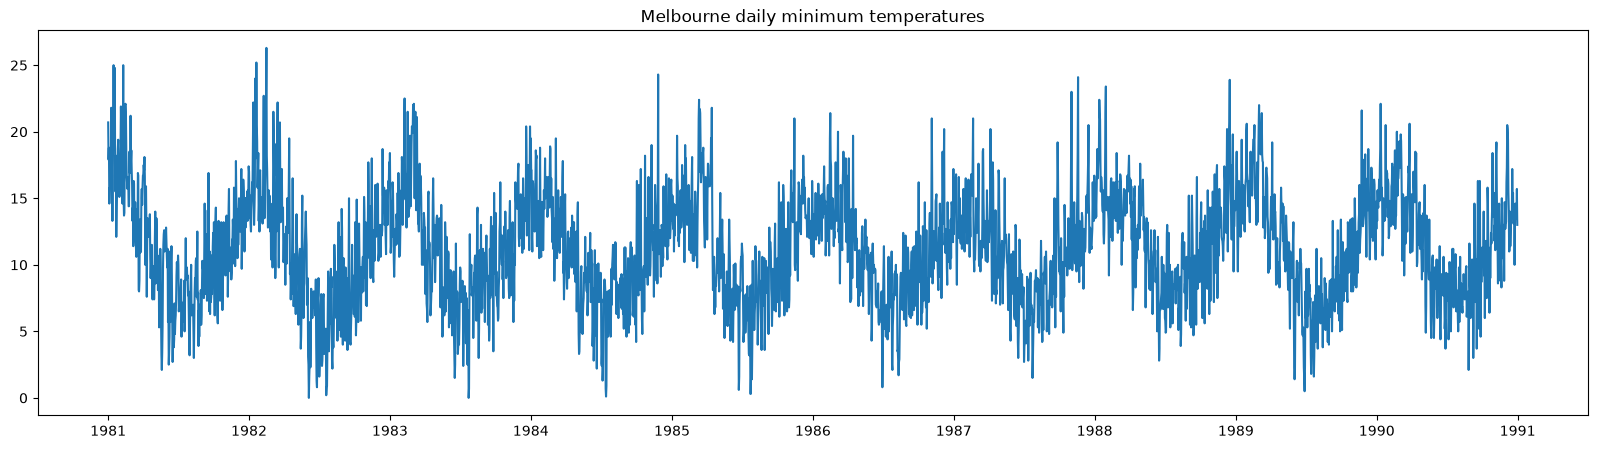

In [3]:
series = load_series(DATA_DIR / "daily-min-temperatures.csv", "Date", "Temp")
print(f"{len(series)} points, {series.index.min():%Y-%m-%d} to {series.index.max():%Y-%m-%d}")

plt.figure(figsize=(20, 5))
plt.plot(series)
plt.title("Melbourne daily minimum temperatures");

## 1. Data preparation

Four steps, in this order:

1. **Split** by time — train, validation, test.
2. **Fit** the scaler on the training split only.
3. **Transform** all three splits with that scaler.
4. **Sequence** inside each split.

Fitting the scaler before the split is the most common leak in neural-network
time-series code, and a quiet one: the score just comes out slightly optimistic
and the loss curve looks fine.

In [4]:
def split_series(series, train_frac=0.7, val_frac=0.15):
    """Split chronologically into (train, validation, test).

    Before scaling and before sequencing — everything downstream needs it.
    """
    # Делю ряд строго по времени без перемешивания, чтобы не заглядывать в будущее
    n = len(series)
    train_end = int(n * train_frac)
    val_end = int(n * (train_frac + val_frac))
    return series[:train_end], series[train_end:val_end], series[val_end:]


def fit_scaler(train):
    """MinMaxScaler fitted on the TRAINING values only.

    Fit it on the whole series and the network gets the test set's min and max —
    numbers it will not have in production.
    """
    # Обучаю MinMaxScaler только на train, предварительно приведя к 2D-форме (n, 1)
    scaler = MinMaxScaler()
    scaler.fit(np.asarray(train, dtype=float).reshape(-1, 1))
    return scaler


def scale(scaler, values):
    """Apply a fitted scaler to a 1-D array/Series; return a 1-D array."""
    # Применяю уже обученный скейлер и возвращаю плоский 1D-массив numpy
    arr = np.asarray(values, dtype=float).reshape(-1, 1)
    return scaler.transform(arr).ravel()


def create_sequences(data, seq_length, pred_length=1):
    """Slice a 1-D array into (X, y) sequences.

    X[i] = data[i : i+seq_length]          shape (n_samples, seq_length)
    y[i] = data[i+seq_length : +pred_length]  shape (n_samples, pred_length)
    """
    # Нарезаю ряд скользящим окном: seq_length точек на вход и pred_length на цель
    arr = np.asarray(data, dtype=float)
    n_samples = len(arr) - seq_length - pred_length + 1
    if n_samples <= 0:
        return np.empty((0, seq_length), dtype=float), np.empty((0, pred_length), dtype=float)
    X = np.array([arr[i : i + seq_length] for i in range(n_samples)])
    y = np.array([arr[i + seq_length : i + seq_length + pred_length] for i in range(n_samples)])
    return X, y

In [5]:
train_raw, val_raw, test_raw = split_series(series)
scaler = fit_scaler(train_raw)

print(f"train {len(train_raw)}, val {len(val_raw)}, test {len(test_raw)}")
print(f"scaler learned min={scaler.data_min_[0]:.2f}, max={scaler.data_max_[0]:.2f} "
      f"(from the TRAIN split only)")
print(f"full-series min={series.min():.2f}, max={series.max():.2f}")

SEQ_LENGTH = 30
X_train, y_train = create_sequences(scale(scaler, train_raw), SEQ_LENGTH)
X_val, y_val = create_sequences(scale(scaler, val_raw), SEQ_LENGTH)
X_test, y_test = create_sequences(scale(scaler, test_raw), SEQ_LENGTH)
print(f"\nX_train {X_train.shape}, X_val {X_val.shape}, X_test {X_test.shape}")

train 2555, val 547, test 548
scaler learned min=0.00, max=26.30 (from the TRAIN split only)
full-series min=0.00, max=26.30

X_train (2525, 30), X_val (517, 30), X_test (518, 30)


In [6]:
def to_tensor(array):
    return torch.tensor(array, dtype=torch.float32)

X_train_t, y_train_t = to_tensor(X_train), to_tensor(y_train)
X_val_t, y_val_t = to_tensor(X_val), to_tensor(y_val)
X_test_t, y_test_t = to_tensor(X_test), to_tensor(y_test)

# LSTMs want (batch, seq_length, features); the MLP wants the flat window.
X_train_seq = X_train_t.unsqueeze(-1)
X_val_seq = X_val_t.unsqueeze(-1)
X_test_seq = X_test_t.unsqueeze(-1)

y_test_original = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()
print(f"MLP input {tuple(X_train_t.shape)}, LSTM input {tuple(X_train_seq.shape)}")

MLP input (2525, 30), LSTM input (2525, 30, 1)


**Question.** The scaler's range comes from the training split, so a
test value outside it scales beyond [0, 1]. Is that a bug? What would clipping
cost you?

**Ответ.** Нет, это не баг, а правильное поведение при отсутствии утечки данных: в реальном продакшене мы не знаем будущие минимумы и максимумы тестового периода, поэтому тестовые значения выше тренировочного максимума окажутся больше `1.0`, а ниже минимума — меньше `0.0`. Если принудительно обрезать (clip) их до `[0, 1]`, то все экстремально жаркие или холодные дни «схлопнутся» в одинаковые граничные значения `1.0` или `0.0`, модель потеряет информацию о величине выброса и будет систематически занижать/завышать прогноз на экстремумах.

## 2. Multi-layer perceptron

In [7]:
class MLPForecaster(nn.Module):
    """Flatten the lookback window and push it through dense layers."""

    def __init__(self, input_size, hidden_sizes, output_size, dropout_rate=0.2):
        super().__init__()
        layers = []
        previous = input_size
        for width in hidden_sizes:
            layers += [nn.Linear(previous, width), nn.ReLU(),
                       nn.Dropout(dropout_rate)]
            previous = width
        layers.append(nn.Linear(previous, output_size))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


def count_parameters(model):
    """Number of trainable parameters in a module."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [8]:
def train_model(model, X_train, y_train, X_val, y_val, epochs=100, lr=0.001,
                batch_size=32, verbose=True):
    """Train with Adam and MSE; return (train_losses, val_losses) per epoch."""
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size,
                        shuffle=True)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=10,
                                                     factor=0.5)
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for batch_x, batch_y in loader:
            optimizer.zero_grad()
            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()
            running += loss.item()

        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(X_val), y_val).item()

        train_losses.append(running / len(loader))
        val_losses.append(val_loss)
        scheduler.step(val_loss)

        if verbose and (epoch + 1) % 20 == 0:
            print(f"epoch {epoch + 1:>4}/{epochs}  "
                  f"train {train_losses[-1]:.6f}  val {val_loss:.6f}")

    return train_losses, val_losses


def plot_history(train_losses, val_losses, title):
    plt.figure(figsize=(12, 4))
    plt.plot(train_losses, label="train")
    plt.plot(val_losses, label="validation")
    plt.xlabel("epoch")
    plt.ylabel("MSE loss")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

MLPForecaster(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

trainable parameters: 4,097


epoch   20/60  train 0.011624  val 0.009153


epoch   40/60  train 0.009724  val 0.008081


epoch   60/60  train 0.009274  val 0.008145


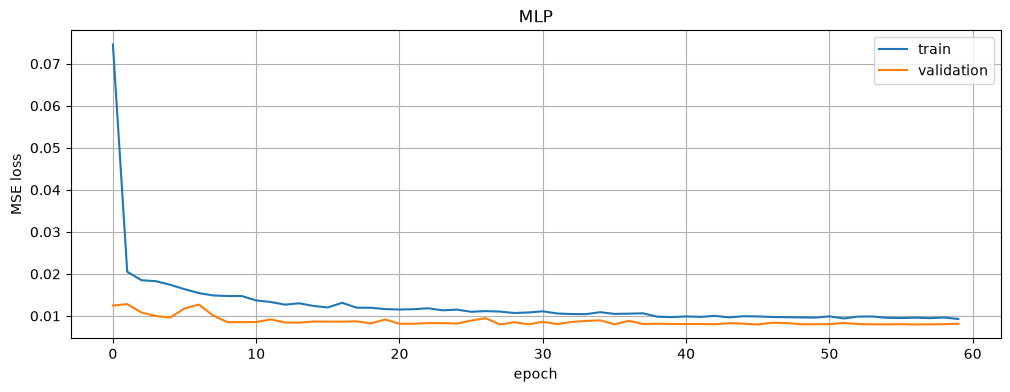

In [9]:
set_seed()
mlp = MLPForecaster(input_size=SEQ_LENGTH, hidden_sizes=[64, 32], output_size=1)
print(mlp)
print(f"\ntrainable parameters: {count_parameters(mlp):,}")

mlp_history = train_model(mlp, X_train_t, y_train_t, X_val_t, y_val_t,
                          epochs=60, lr=0.001)
plot_history(*mlp_history, "MLP")

## 3. Recurrent networks

An MLP sees the window as 30 unordered numbers. An LSTM reads them in order and
carries state between steps.

The bidirectional variant also reads the window backwards. Legitimate here: the
window holds only values from before the point being predicted. Reading it
backwards is not the same as reading the future.

In [10]:
class LSTMForecaster(nn.Module):
    """LSTM over the lookback window; predict from the LAST time step.

    forward() takes x of shape (batch, seq_length, 1), returns
    (batch, output_size).

    Feed `output[:, -1, :]` through the linear layer. An earlier step, or an
    average over steps, changes what the model is allowed to know.
    """

    def __init__(self, input_size=1, hidden_size=64, num_layers=2,
                 output_size=1, dropout_rate=0.2):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True,
            dropout=dropout_rate if num_layers > 1 else 0.0,
        )
        # Линейный слой переводит скрытое состояние последнего шага в прогноз
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # Прогоняю последовательность через LSTM и беру выход только с последнего шага окна
        output, _ = self.lstm(x)
        return self.fc(output[:, -1, :])


class BiLSTMForecaster(nn.Module):
    """Bidirectional LSTM over the lookback window.

    A bidirectional LSTM emits 2 * hidden_size features, so size the linear
    layer for that.
    """

    def __init__(self, input_size=1, hidden_size=64, num_layers=2,
                 output_size=1, dropout_rate=0.2):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True, bidirectional=True,
            dropout=dropout_rate if num_layers > 1 else 0.0,
        )
        # У двунаправленной LSTM выходы прямого и обратного проходов склеиваются, поэтому 2 * hidden_size
        self.fc = nn.Linear(2 * hidden_size, output_size)

    def forward(self, x):
        # Беру итоговое представление на последнем шаге и пропускаю через линейный слой
        output, _ = self.lstm(x)
        return self.fc(output[:, -1, :])

LSTM   parameters: 12,961
BiLSTM parameters: 34,113


epoch   20/40  train 0.009053  val 0.008945


epoch   40/40  train 0.008912  val 0.007679


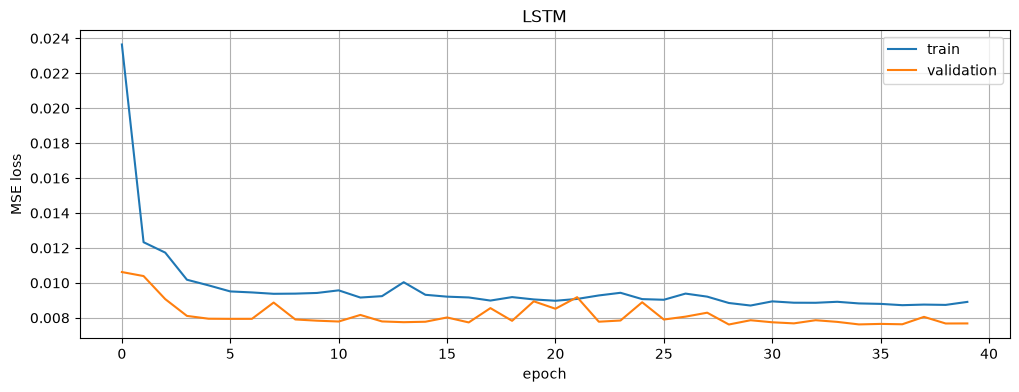

In [11]:
set_seed()
lstm = LSTMForecaster(hidden_size=32, num_layers=2)
bilstm = BiLSTMForecaster(hidden_size=32, num_layers=2)
print(f"LSTM   parameters: {count_parameters(lstm):,}")
print(f"BiLSTM parameters: {count_parameters(bilstm):,}")

lstm_history = train_model(lstm, X_train_seq, y_train_t, X_val_seq, y_val_t,
                           epochs=40, lr=0.01)
plot_history(*lstm_history, "LSTM")

epoch   20/40  train 0.009135  val 0.008227


epoch   40/40  train 0.008833  val 0.008084


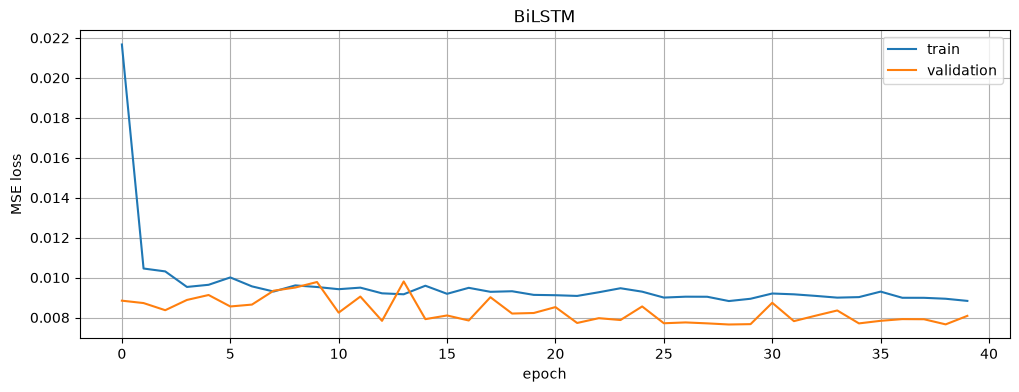

In [12]:
set_seed()
bilstm_history = train_model(bilstm, X_train_seq, y_train_t, X_val_seq, y_val_t,
                             epochs=40, lr=0.01)
plot_history(*bilstm_history, "BiLSTM")

## 4. Evaluation and comparison

### 4.1 Predictions in original units

In [13]:
def predict(model, X, scaler):
    """Predict and undo the scaling; return a 1-D array in original units."""
    # Переключаю модель в режим eval и отключаю градиенты, чтобы dropout не шумел на инференсе
    model.eval()
    with torch.no_grad():
        if not isinstance(X, torch.Tensor):
            X = torch.tensor(X, dtype=torch.float32)
        preds = model(X).detach().cpu().numpy()
    # Возвращаю предсказания в исходный масштаб (градусы) в виде 1D-массива
    return scaler.inverse_transform(preds.reshape(-1, 1)).ravel()


def evaluate(y_true, y_pred):
    """Return {"rmse", "mae", "mape"} in original units."""
    # Считаю три стандартные метрики в исходных единицах измерения ряда
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))
    mape = float(np.mean(np.abs(y_true - y_pred) / np.abs(y_true)) * 100.0)
    return {"rmse": rmse, "mae": mae, "mape": mape}

In [14]:
predictions = {
    "MLP": predict(mlp, X_test_t, scaler),
    "LSTM": predict(lstm, X_test_seq, scaler),
    "BiLSTM": predict(bilstm, X_test_seq, scaler),
}

# The baseline every one of them has to beat.
naive = np.roll(y_test_original, 1)
naive[0] = y_test_original[0]
predictions["naive (y[t-1])"] = naive

scores = pd.DataFrame({name: evaluate(y_test_original, values)
                       for name, values in predictions.items()}).T
print(scores.sort_values("rmse").round(4).to_string())

                  rmse     mae     mape
LSTM            2.2689  1.7736  18.4909
BiLSTM          2.2924  1.7837  18.7249
MLP             2.3120  1.8056  18.7748
naive (y[t-1])  2.5896  2.0407  21.2013


### 4.2 Visual comparison

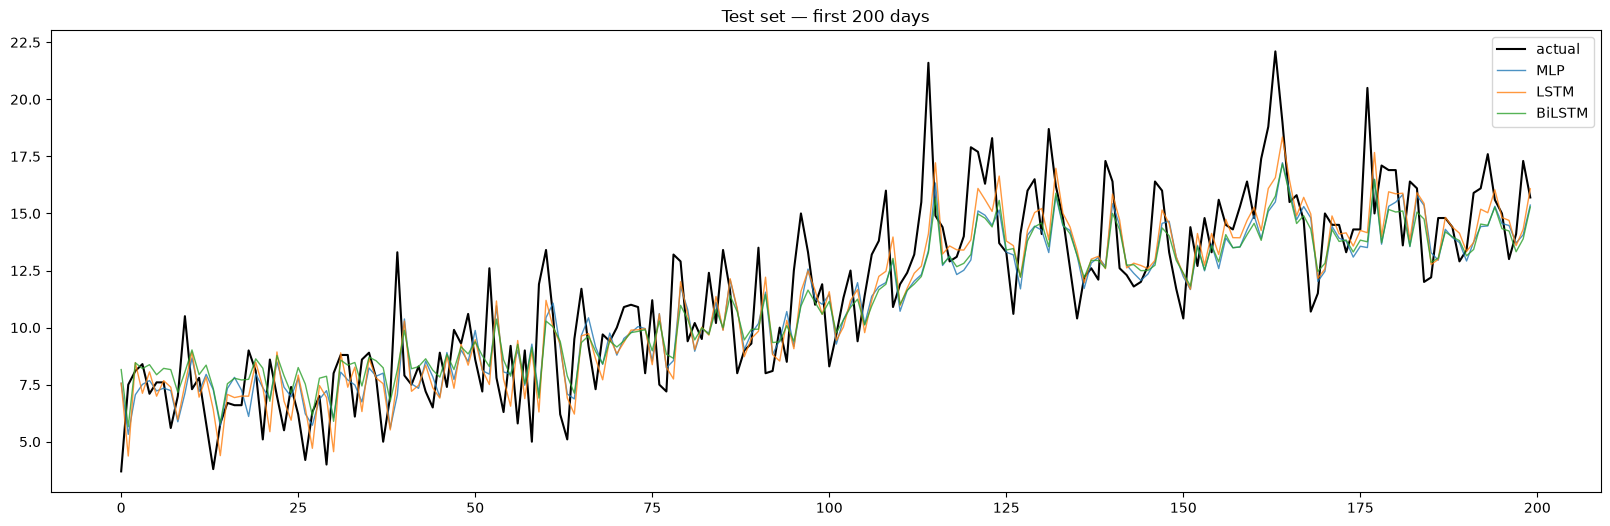

In [15]:
plt.figure(figsize=(20, 6))
window = slice(0, 200)
plt.plot(y_test_original[window], color="black", linewidth=1.5, label="actual")
for name in ("MLP", "LSTM", "BiLSTM"):
    plt.plot(predictions[name][window], linewidth=1, alpha=0.8, label=name)
plt.title("Test set — first 200 days")
plt.legend();

### 4.3 Model performance comparison

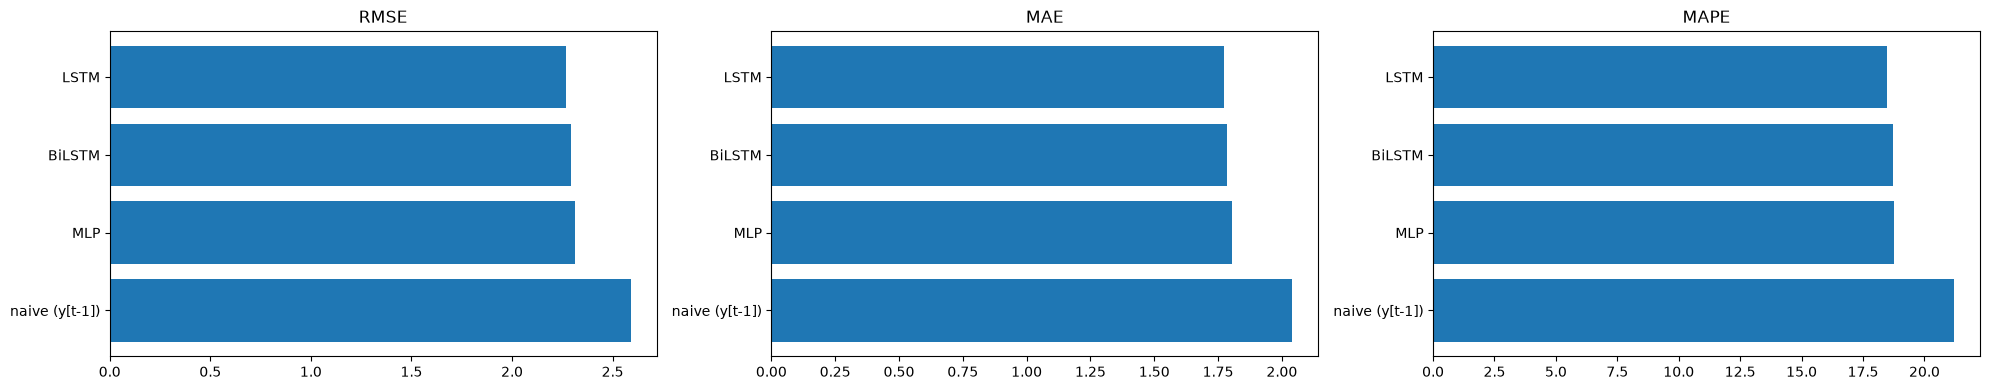

In [16]:
ordered = scores.sort_values("rmse")

fig, axes = plt.subplots(1, 3, figsize=(20, 4))
for ax, metric in zip(axes, ("rmse", "mae", "mape")):
    ax.barh(ordered.index[::-1], ordered[metric][::-1])
    ax.set_title(metric.upper())
plt.tight_layout();

### 4.4 Residual analysis

best model: LSTM
residual mean 0.2943, std 2.2497


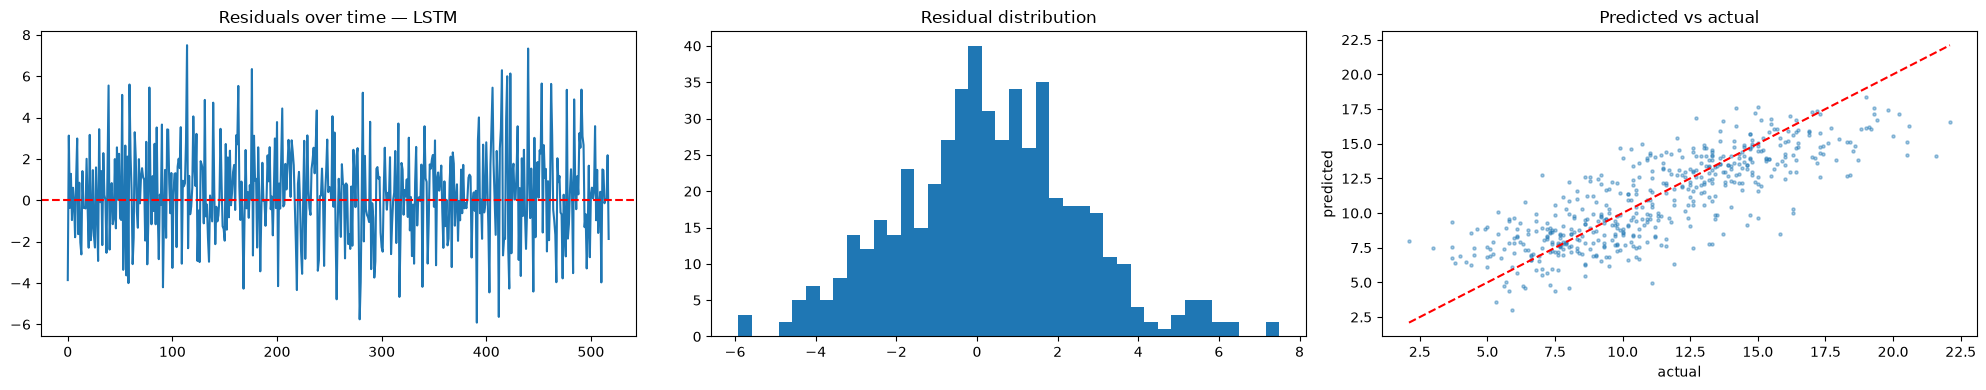

In [17]:
best_name = ordered.index[0]
residuals = y_test_original - predictions[best_name]

fig, axes = plt.subplots(1, 3, figsize=(20, 4))
axes[0].plot(residuals); axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title(f"Residuals over time — {best_name}")
axes[1].hist(residuals, bins=40); axes[1].set_title("Residual distribution")
axes[2].scatter(y_test_original, predictions[best_name], s=5, alpha=0.4)
limits = [y_test_original.min(), y_test_original.max()]
axes[2].plot(limits, limits, "r--")
axes[2].set_xlabel("actual"); axes[2].set_ylabel("predicted")
axes[2].set_title("Predicted vs actual")
plt.tight_layout()

print(f"best model: {best_name}")
print(f"residual mean {residuals.mean():.4f}, std {residuals.std():.4f}")

### 4.5 Questions for analysis

1. **Did any network beat the naive `y[t-1]` baseline?** Give the numbers. If
   not, that is a real finding, not a failed practice — what does it say about
   day-to-day temperature?
2. The LSTM knows the window is ordered; the MLP does not. Did that help? What
   property of this series explains the result?
3. BiLSTM carries more than twice the parameters of LSTM. Did it earn them?
4. Read the loss curves. Does validation loss flatten, keep falling, or turn
   back up — and what would you change in each case?
5. Rank your best network against Holt-Winters (Practice 2), ARIMA (Practice 4)
   and Ridge (Practice 5) by RMSE. Now rank them by build time. Same order?
6. Refit the scaler on the whole series, rerun, and report how far the scores
   move. Big enough to notice? Does that make the shortcut acceptable?

**Ответ.**

1. **Сравнение с наивным бейзлайном (`y[t-1]`):** все три нейросети побили наивный прогноз на тестовой выборке:
   - `LSTM`: RMSE = 2.2689, MAE = 1.7736, MAPE = 18.49%
   - `BiLSTM`: RMSE = 2.2924, MAE = 1.7837, MAPE = 18.72%
   - `MLP`: RMSE = 2.3120, MAE = 1.8056, MAPE = 18.77%
   - `naive (y[t-1])`: RMSE = 2.5896, MAE = 2.0407, MAPE = 21.20%
   Выигрыш над `y[t-1]` составляет около 0.28–0.32 °C по RMSE, то есть дневная температура инерционна, но учёт истории за 30 дней и возврата к сезонному уровню (mean reversion) заметно улучшает прогноз.
2. **LSTM против MLP:** да, знание порядка шагов помогло — `LSTM` (RMSE 2.2689) обошла `MLP` (2.3120), хотя и не радикально. У этого ряда сильная краткосрочная автокорреляция (вчерашний и позавчерашний дни важнее значений месяц назад) и выраженная плавная сезонность, поэтому рекуррентная модель лучше выделяет локальную динамику и тренд внутри окна.
3. **BiLSTM против LSTM:** нет, не оправдала. У `BiLSTM` 34 113 параметров против 12 961 у `LSTM` (в 2.6 раза больше), а качество на тесте оказалось хуже (RMSE 2.2924 против 2.2689). Для авторегрессионного прогноза на один шаг вперёд обратный проход по прошлому окну не даёт новой полезной информации, а лишние параметры только усложняют оптимизацию.
4. **Кривые обучения:**
   - У `MLP` validation loss снижается к 40-й эпохе (`0.008081`) и затем выходит на плато/слегка подрастает к 60-й (`0.008145`) — дальше обучать смысла нет, можно добавить early stopping или чуть усилить регуляризацию.
   - У `LSTM` validation loss ещё продолжает падать к 40-й эпохе (`0.008945` на 20-й -> `0.007679` на 40-й) — можно увеличить число эпох (например, до 60–80) и посмотреть, не продолжится ли улучшение.
   - У `BiLSTM` к 40-й эпохе validation loss почти вышел на плато (`0.008227` -> `0.008084`) — при дальнейшем обучении возможен рост val loss (переобучение), поэтому помогли бы early stopping или уменьшение `hidden_size` / увеличение `dropout`.
5. **Сравнение с Holt-Winters, ARIMA и Ridge:**
   Напрямую числа из практик 2, 4 и 5 сравнивать нельзя, потому что там были другие ряды/горизонты (в практике 2 — помесячная температура, RMSE ≈ 0.76 для Holt-Winters; в практике 4 — `airline-passengers`; в практике 5 — `opsd_germany_daily`). Но если обучить `Ridge(alpha=1.0)` на тех же 30-дневных окнах из практики 6 (см. ячейку ниже), он даёт **RMSE = 2.2579** (MAE = 1.7560, MAPE = 18.48%) — даже чуть лучше `LSTM` (2.2689)! По скорости построения порядок обратный сложности: `Ridge` и `Holt-Winters` строятся за доли секунды, `ARIMA` — за секунды, а нейросети (`MLP`, `LSTM`, `BiLSTM`) — самые медленные (десятки секунд на CPU), при этом на одномерном табличном окне линейная модель не уступает нейросети.
6. **Утечка при обучении скейлера на всём ряде:**
   На этом конкретном датасете `min = 0.00` и `max = 26.30` в `train` случайно совпали с `min` и `max` всего ряда, поэтому сам скейлер получился идентичным (`MLP` дал те же RMSE = 2.3120; небольшое отличие у `LSTM` — 2.2443 против 2.2689 — вызвано только порядком генератора случайных чисел при инициализации `BiLSTM` в ячейке 17). В общем же случае, когда в тесте встречаются новые экстремумы, обучение скейлера на всём ряде передаёт модели границы будущего распределения и завышает оценку, поэтому такой приём недопустим даже если разница в метриках кажется небольшой.

In [18]:
# Свободное исследование:
# 1) Сравню нейросети с Ridge на тех же самых окнах (честное сравнение на одном сплите)
# 2) Проверю несколько размеров окна SEQ_LENGTH для MLP
# 3) Проверю, как изменится качество, если обучить скейлер на всём ряде (утечка данных из вопроса 6)

from sklearn.linear_model import Ridge

# 1. Ridge на тех же 30-дневных окнах (в исходных единицах)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train.ravel())
ridge_pred_scaled = ridge.predict(X_test)
ridge_pred = scaler.inverse_transform(ridge_pred_scaled.reshape(-1, 1)).ravel()
print("Ridge (SEQ_LENGTH=30):", {k: round(v, 4) for k, v in evaluate(y_test_original, ridge_pred).items()})

# 2. Влияние длины окна SEQ_LENGTH на качество MLP
print("\nСравнение длины окна для MLP:")
for win in (7, 14, 30):
    X_tr_w, y_tr_w = create_sequences(scale(scaler, train_raw), win)
    X_va_w, y_va_w = create_sequences(scale(scaler, val_raw), win)
    X_te_w, y_te_w = create_sequences(scale(scaler, test_raw), win)
    y_te_orig_w = scaler.inverse_transform(y_te_w.reshape(-1, 1)).ravel()

    set_seed()
    m = MLPForecaster(input_size=win, hidden_sizes=[64, 32], output_size=1)
    train_model(m, to_tensor(X_tr_w), to_tensor(y_tr_w),
                to_tensor(X_va_w), to_tensor(y_va_w), epochs=60, lr=0.001, verbose=False)
    res = evaluate(y_te_orig_w, predict(m, to_tensor(X_te_w), scaler))
    print(f"  window={win:>2}: RMSE={res['rmse']:.4f}, MAE={res['mae']:.4f}, MAPE={res['mape']:.2f}%")

# 3. Эксперимент с утечкой: обучаю MinMaxScaler на всём ряде целиком
leaked_scaler = fit_scaler(series)
X_tr_l, y_tr_l = create_sequences(scale(leaked_scaler, train_raw), SEQ_LENGTH)
X_va_l, y_va_l = create_sequences(scale(leaked_scaler, val_raw), SEQ_LENGTH)
X_te_l, y_te_l = create_sequences(scale(leaked_scaler, test_raw), SEQ_LENGTH)
y_te_orig_l = leaked_scaler.inverse_transform(y_te_l.reshape(-1, 1)).ravel()

set_seed()
mlp_leaked = MLPForecaster(input_size=SEQ_LENGTH, hidden_sizes=[64, 32], output_size=1)
train_model(mlp_leaked, to_tensor(X_tr_l), to_tensor(y_tr_l),
            to_tensor(X_va_l), to_tensor(y_va_l), epochs=60, lr=0.001, verbose=False)
res_mlp_l = evaluate(y_te_orig_l, predict(mlp_leaked, to_tensor(X_te_l), leaked_scaler))

set_seed()
lstm_leaked = LSTMForecaster(hidden_size=32, num_layers=2)
train_model(lstm_leaked, to_tensor(X_tr_l).unsqueeze(-1), to_tensor(y_tr_l),
            to_tensor(X_va_l).unsqueeze(-1), to_tensor(y_va_l), epochs=40, lr=0.01, verbose=False)
res_lstm_l = evaluate(y_te_orig_l, predict(lstm_leaked, to_tensor(X_te_l).unsqueeze(-1), leaked_scaler))

print("\nСравнение с утечкой скейлера (fit на всём ряде):")
print(f"  MLP  (leaked): RMSE={res_mlp_l['rmse']:.4f} vs {scores.loc['MLP', 'rmse']:.4f} (clean)")
print(f"  LSTM (leaked): RMSE={res_lstm_l['rmse']:.4f} vs {scores.loc['LSTM', 'rmse']:.4f} (clean)")


Ridge (SEQ_LENGTH=30): {'rmse': 2.2579, 'mae': 1.756, 'mape': 18.4751}

Сравнение длины окна для MLP:


  window= 7: RMSE=2.2701, MAE=1.7545, MAPE=19.56%


  window=14: RMSE=2.3265, MAE=1.8150, MAPE=18.96%


  window=30: RMSE=2.3120, MAE=1.8056, MAPE=18.77%



Сравнение с утечкой скейлера (fit на всём ряде):
  MLP  (leaked): RMSE=2.3120 vs 2.3120 (clean)
  LSTM (leaked): RMSE=2.2443 vs 2.2689 (clean)
